# 基于检索增强生成（RAG）的知识问答系统设计

**课程大作业 · 实验报告 Notebook**

以《自然语言处理导论》（张奇、桂韬、黄萱菁，2023 网络预览版，604 页）作为私有知识库，
从零实现一条完整的 RAG 流水线：**PDF 读取 → 文本清洗 → 文本切分 → 文本向量化 → FAISS 向量检索 → Prompt 构建 → 大模型生成答案**。

| 项目 | 内容 |
| --- | --- |
| 姓名 / 学号 | ＿＿＿＿＿＿ / ＿＿＿＿＿＿ |
| 班级 / 专业 | ＿＿＿＿＿＿ |
| 语料规模 | 正文 506 页，原始 58.4 万字符 → 清洗后 42.4 万字符 → 切分 1700 个文本块 |
| 技术栈 | Python 3.13 · PyMuPDF · sentence-transformers（bge-small-zh-v1.5）· FAISS · DeepSeek API |
| 硬件 | CPU 环境，无需 GPU |

> **运行方式**：`jupyter notebook` 打开本文件，从上到下依次执行（Run All 即可）。
> 首次运行会自动下载嵌入模型（约 95 MB，通过 hf-mirror 镜像）；
> 若要真实调用大模型生成答案，需要配置 DeepSeek API Key，配置方法见「6.2 调用大语言模型」一节。
> 未配置 Key 时，Notebook 会自动降级为「只检索、展示证据原文」模式，全部单元格仍可正常执行。


## 一、实验目的与要求对照

**实验目的**：理解 RAG 把「检索」与「生成」结合起来的基本思想；掌握 PDF 解析、清洗、切分、向量化、向量检索的全流程；
理解向量检索与传统关键词检索的区别；体会 RAG 在缓解大模型幻觉、补充私有知识方面的作用。

本节把实验要求的 7 个步骤与 Notebook 中的实现位置一一对应，便于批阅：

| 实验要求 | 实现位置 | 关键方法 / 输出 |
| --- | --- | --- |
| ① PDF 文档读取 | 2.1 | PyMuPDF 逐页抽取文本，保留页码，统计每页字符数 |
| ② 文本清洗 | 2.2 | 6 条正则规则清洗页眉页脚、目录点线、字体乱码、引用角标；软换行合并 |
| ③ 文本切分 | 2.3 | 自实现递归字符切分器（标点优先级 + 邻居重叠），块级元数据（章 / 页） |
| ④ 文本向量化 | 2.4 | bge-small-zh-v1.5（512 维，中文语义模型），L2 归一化 |
| ⑤ FAISS 向量检索 | 2.5 | IndexFlatIP 精确检索 + IndexIVFFlat 倒排检索对比 |
| ⑥ Prompt 构建 | 2.6 | 系统提示 + 带编号与出处的参考资料 + 拒答约束 |
| ⑦ 调用大模型生成 | 6.1 | DeepSeek（OpenAI 兼容接口），低温度、可追溯引用 |
| 附加：对比与消融 | 3、4 | 向量检索 vs TF-IDF 关键词检索；top_k、chunk_size 消融；有 / 无 RAG 幻觉对比 |

### 整体流程

```mermaid
flowchart LR
    A[PDF 604 页] --> B[逐页文本抽取<br/>PyMuPDF]
    B --> C[文本清洗<br/>去页眉/乱码/角标]
    C --> D[递归切分<br/>400 字/块, 重叠 80]
    D --> E[向量化<br/>bge-small-zh 512 维]
    E --> F[(FAISS 索引<br/>IndexFlatIP)]
    Q[用户问题] --> Q1[同一编码器<br/>加查询前缀]
    Q1 --> G[Top-K 检索]
    F --> G
    G --> H[Prompt 组装<br/>证据+编号+出处]
    H --> I[DeepSeek 生成]
    I --> J[带引用的答案]
```

> 文本版流程：`PDF → 抽取 → 清洗 → 切分 → 向量化 → 入 FAISS 库`；提问时 `问题 → 向量化 → 相似度检索 Top-K → 拼 Prompt → LLM → 答案`。


In [1]:
# 若在新环境中首次运行，请先取消下一行注释安装依赖（约 3 分钟，主要耗时在 torch）
# !pip install pymupdf sentence-transformers faiss-cpu openai pandas matplotlib tqdm scikit-learn -q

import sys, platform, importlib

print("Python :", sys.version.split()[0], "|", platform.system(), platform.machine())
for name in ["pymupdf", "sentence_transformers", "faiss", "openai", "pandas", "matplotlib", "sklearn"]:
    try:
        mod = importlib.import_module(name)
        print(f"  {name:22s}{getattr(mod, '__version__', 'ok')}")
    except ImportError:
        print(f"  {name:22s}未安装 ← 请执行上一行的 pip install")


Python : 3.13.14 | Windows AMD64


  pymupdf               2.0


  sentence_transformers 6.1.0
  faiss                 1.15.1


  openai                3.35.1
  pandas                3.0.6
  matplotlib            3.11.2
  sklearn               1.9.1


In [2]:
import os
from pathlib import Path

# HuggingFace 官方域名在国内无法直连，统一切换到镜像站（必须在 import sentence_transformers 之前设置）
os.environ.setdefault("HF_ENDPOINT", "https://hf-mirror.com")
# 镜像站不支持 HuggingFace 的 Xet 存储后端，必须回退普通 HTTP 下载，否则报 401
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")

CFG = dict(
    pdf_path      = Path("自然语言处理导论.pdf"),
    body_start    = 20,     # 0-based PDF 页索引；第 20 页是书内正文第 1 页（前面是封面、序、目录）
    body_end      = 525,    # 最后一页正文；之后再往后是参考文献与索引，不纳入知识库
    chunk_size    = 400,    # 每个文本块的目标长度（字符）
    chunk_overlap = 80,     # 相邻块重叠长度，避免语义被硬切断
    embed_model   = "BAAI/bge-small-zh-v1.5",
    query_prefix  = "为这个句子生成表示以用于检索相关文章：",   # bge 官方推荐的查询侧前缀
    top_k         = 5,
    llm_base_url  = "https://api.deepseek.com",
    llm_model     = "deepseek-chat",
    temperature   = 0.1,
)

WORK_DIR  = Path(".").resolve()
INDEX_DIR = WORK_DIR / "rag_index"
INDEX_DIR.mkdir(exist_ok=True)

# 嵌入模型：优先用本地已下载的副本（离线可用），否则用仓库名在线加载
LOCAL_MODEL = WORK_DIR / "models" / "bge-small-zh-v1.5"
CFG["embed_model"] = str(LOCAL_MODEL) if (LOCAL_MODEL / "config.json").exists() else "BAAI/bge-small-zh-v1.5"


def load_api_key() -> str:
    """优先读环境变量 DEEPSEEK_API_KEY，其次读同目录下的 deepseek_api_key.txt（一行一个 key）"""
    key = os.environ.get("DEEPSEEK_API_KEY", "").strip()
    f = WORK_DIR / "deepseek_api_key.txt"
    if not key and f.exists():
        key = f.read_text(encoding="utf-8").strip().splitlines()[0].strip()
    return key


DEEPSEEK_API_KEY = load_api_key()

print("语料文件 :", CFG["pdf_path"].resolve().name, "（存在）" if CFG["pdf_path"].exists() else "（缺失！）")
print("嵌入模型 :", CFG["embed_model"])
print("工作目录 :", WORK_DIR)
print("索引目录 :", INDEX_DIR)
print("DeepSeek Key :", "已配置 ✔" if DEEPSEEK_API_KEY else "未配置 → 生成步骤将自动降级为“仅检索并展示证据”")


语料文件 : 自然语言处理导论.pdf （存在）
嵌入模型 : C:\Users\32048\Desktop\RAG\models\bge-small-zh-v1.5
工作目录 : C:\Users\32048\Desktop\RAG
索引目录 : C:\Users\32048\Desktop\RAG\rag_index
DeepSeek Key : 已配置 ✔


## 二、RAG 基本流程实现

### 2.1 步骤一：PDF 文档读取

使用 PyMuPDF（fitz）逐页读取。相比 `pdfplumber`，PyMuPDF 对带公式、图表的 LaTeX 排版 PDF 抽取更快、版面顺序更稳。
关键是**保留页码**：后续每个文本块都要能回溯到「第几页」，这是答案给出出处的依据。

同时先做一次数据探查——页数、字符量、每页字符数分布，用来判断 PDF 是文本型还是扫描型、有没有空白页需要处理。


文件       : 自然语言处理导论.pdf  36.7 MB  共 604 页
索引范围   : PDF 第 21–526 页（＝书内正文 pp.1–508），共 506 页
原始字符数 : 583,987
平均每页   : 1154 字符 → PDF 为文本型，可直接抽取（无需 OCR）


,count,mean,std,min,25%,50%,75%,max
字符数,506.0,1154.1,506.2,36.0,930.5,1106.0,1308.5,6878.0


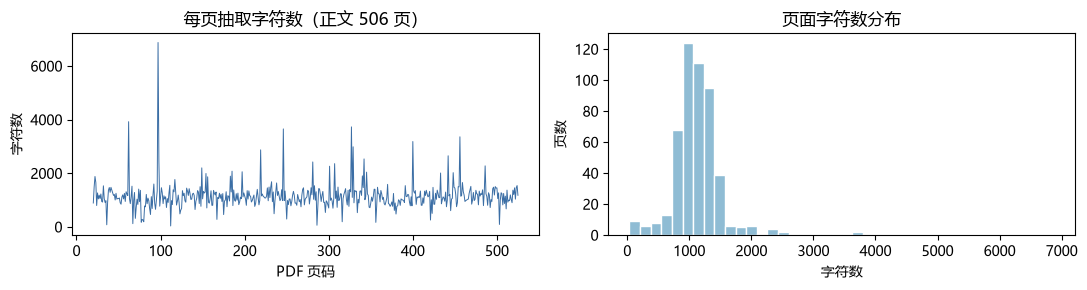

In [3]:
import pymupdf
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]   # 让图表能显示中文
plt.rcParams["axes.unicode_minus"] = False

doc = pymupdf.open(CFG["pdf_path"])
raw_pages = [(i, doc[i].get_text()) for i in range(CFG["body_start"], CFG["body_end"] + 1)]

raw_total = sum(len(t) for _, t in raw_pages)
print(f"文件       : {CFG['pdf_path'].name}  {CFG['pdf_path'].stat().st_size / 1e6:.1f} MB  共 {doc.page_count} 页")
print(f"索引范围   : PDF 第 {CFG['body_start'] + 1}–{CFG['body_end'] + 1} 页（＝书内正文 pp.1–508），共 {len(raw_pages)} 页")
print(f"原始字符数 : {raw_total:,}")
print(f"平均每页   : {raw_total / len(raw_pages):.0f} 字符 → PDF 为文本型，可直接抽取（无需 OCR）")

df_raw = pd.DataFrame({"pdf页": [p for p, _ in raw_pages], "字符数": [len(t) for _, t in raw_pages]})
display(df_raw["字符数"].describe().round(1).to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(df_raw["pdf页"], df_raw["字符数"], lw=0.7, color="#3b6ea5")
axes[0].set(title="每页抽取字符数（正文 506 页）", xlabel="PDF 页码", ylabel="字符数")
axes[1].hist(df_raw["字符数"], bins=40, color="#8fbcd4", edgecolor="white")
axes[1].set(title="页面字符数分布", xlabel="字符数", ylabel="页数")
plt.tight_layout()
plt.show()


### 2.2 步骤二：文本清洗

直接从 LaTeX 排版 PDF 抽出的文本夹带大量「非正文噪声」，如果不清洗会严重污染向量语义。本书中实际观察到的噪声有五类：

| # | 噪声类型 | 实例 | 处理方式 |
| --- | --- | --- | --- |
| 1 | 偶数页页眉 | `2 自然语言处理导论-- 张奇、桂韬、黄萱菁` | 正则整行删除，并**顺带解析出书内页码** |
| 2 | 奇数页页眉 | `绪论3`、`词汇分析31` | 用目录解析出的章标题表做白名单匹配后删除 |
| 3 | 目录点线 | `1.1 自然语言处理基本概念 . . . . . 1` | 匹配连续点线行删除 |
| 4 | 图表内嵌字体乱码 | `wAlHMarUIcRF8LZ0VfOg=">AB/XicbVC7SgNBFL0bXzG+...` | 匹配 40 位以上字母数字串删除 |
| 5 | 引用角标 / 软换行 | `…理论与方法[1]。` ／ 一句话被折断成多行 | 角标替换为空；中文断行直接拼接，英文之间补空格 |

另外还删掉了「纯数字 / 纯符号行」——它们来自坐标轴刻度和矢量图形，对语义毫无贡献。

**清洗顺序很关键**：先按行判定噪声（此时行结构还在），再合并软换行（此时会产生长段落），顺序反了就再也分不清哪行是页眉了。


In [4]:
import re
import collections

CN = r"\u4e00-\u9fa5"
RE_HEADER_EVEN = re.compile(r"^(\d{1,4})\s*自然语言处理导论")            # 偶数页页眉：2 自然语言处理导论-- 张奇…
RE_HEADER_ODD = re.compile(rf"^([{CN}]{{2,8}})(\d{{1,4}})$")             # 奇数页页眉：绪论3 / 词汇分析31
RE_PAGE_ONLY = re.compile(r"^\d{1,4}$")                                  # 孤立页码
RE_TOC_DOTS = re.compile(r"(\.\s*){4,}\d{1,4}$")                         # 目录点线行
RE_JUNK_TOKEN = re.compile(r"[A-Za-z0-9+/=<>_]{40,}")                    # PDF 内嵌字体导致的乱码串
RE_CITE = re.compile(r"\[\d{1,3}(?:[,，\-–]\s*\d{1,3})*\]")              # 引用角标 [12] / [3,4]
RE_HEAD_NUM = re.compile(r"^\d{1,2}(\.\d{1,2}){0,2}\.?\s+\S")            # 章节号标题 1.1 / 2.3.4


def read_toc(doc):
    """从目录页解析「章号 → (章标题, 书内页码)」和「(章, 节) → (节标题, 书内页码)」

    解析目录有两个用处：① 作为奇数页页眉的白名单；② 给每个文本块打上章 / 节元数据。
    """
    chapters, sections, lines = {}, {}, []
    for i in range(10, 19):                       # 本书目录位于 PDF 第 11–19 页
        lines += doc[i].get_text().split("\n")
    for ln in lines:
        s = ln.strip()
        m = re.match(r"^(\d{1,2})\s+(\S+?)[.\s]{4,}(\d{1,4})$", s)
        if m:
            chapters.setdefault(int(m.group(1)), (m.group(2), int(m.group(3))))
            continue
        m = re.match(r"^(\d{1,2})\.(\d{1,2})\s+(\S+?)[.\s]{4,}(\d{1,4})$", s)
        if m:
            sections[(int(m.group(1)), int(m.group(2)))] = (m.group(3), int(m.group(4)))
    return chapters, sections


CHAPTERS, SECTIONS = read_toc(doc)
CHAPTER_TITLES = {v[0] for v in CHAPTERS.values()}
print(f"目录解析结果：{len(CHAPTERS)} 章 / {len(SECTIONS)} 节")
for no, (title, pg) in sorted(CHAPTERS.items()):
    print(f"  第{no:>2}章  {title:<8s}  p.{pg}")


def clean_page(raw: str, stats: collections.Counter):
    """逐行清洗一页文本，返回 (保留的行列表, 该书页的书内页码)"""
    book_page, lines = None, []
    for ln in raw.split("\n"):
        s = ln.strip()
        if not s:
            continue
        m = RE_HEADER_EVEN.match(s)                       # 噪声 1：偶数页页眉，同时拿到书内页码
        if m:
            book_page = int(m.group(1)); stats["页眉页脚"] += 1; continue
        m = RE_HEADER_ODD.match(s)                        # 噪声 2：奇数页页眉（章标题+页码）
        if m and m.group(1) in CHAPTER_TITLES:
            book_page = int(m.group(2)); stats["页眉页脚"] += 1; continue
        if RE_PAGE_ONLY.fullmatch(s):
            stats["孤立页码"] += 1; continue
        if RE_TOC_DOTS.search(s):                         # 噪声 3
            stats["目录点线"] += 1; continue
        if RE_JUNK_TOKEN.search(s):                       # 噪声 4
            stats["字体乱码串"] += 1; continue
        if len(re.findall(rf"[{CN}]", s)) == 0 and not re.search(r"[A-Za-z]{3,}", s):
            stats["纯数字/符号行"] += 1; continue          # 坐标轴刻度、矢量杂点
        s = re.sub(r"\s+", " ", RE_CITE.sub("", s))        # 噪声 5：去引用角标并压缩空白
        if len(re.findall(r"[A-Za-z0-9]", s)) > 0.6 * len(s):
            stats["英文密集行（文献/图表）"] += 1; continue
        lines.append(s)
    return lines, book_page


def join_lines(lines):
    """行级合并：中文软换行直接拼接；英文与英文之间补空格；行尾连字符去掉避免断词"""
    out = ""
    for s in lines:
        if not out:
            out = s
        elif out.endswith("-"):
            out = out[:-1] + s
        elif re.match(r"[A-Za-z0-9,.);:]$", out[-1]) and re.match(r"[A-Za-z0-9(]", s[0]):
            out += " " + s
        else:
            out += s
    return out


# ---- 清洗前后对比：挑一个图表残留最多的页面（PDF 第 22 页，含图 1.1 时间线）----
demo_idx = 21
raw_demo = doc[demo_idx].get_text()
demo_stats = collections.Counter()
demo_lines, demo_book_page = clean_page(raw_demo, demo_stats)
demo_clean = join_lines(demo_lines)

print(f"\n【清洗前】PDF 第 {demo_idx + 1} 页，{len(raw_demo)} 字符")
print("-" * 80)
print(raw_demo[:600])
print(f"\n【清洗后】书内 p.{demo_book_page}，{len(demo_clean)} 字符，删除明细 {dict(demo_stats)}")
print("-" * 80)
print(demo_clean[:600])


目录解析结果：14 章 / 86 节


  第 1章  绪论        p.1
  第 2章  词汇分析      p.18
  第 3章  句法分析      p.49
  第 4章  语义分析      p.94
  第 5章  篇章分析      p.149
  第 6章  语言模型      p.185
  第 7章  信息抽取      p.217
  第 8章  机器翻译      p.268
  第 9章  情感分析      p.298
  第10章  智能问答      p.338
  第11章  文本摘要      p.371
  第12章  知识图谱      p.403
  第13章  模型稳健性     p.455
  第14章  模型可解释性    p.485

【清洗前】PDF 第 22 页，1492 字符
--------------------------------------------------------------------------------
2 自然语言处理导论-- 张奇、桂韬、黄萱菁
1.1.1 自然语言处理简史
自然语言处理的研究历史可以追溯到1947 年，当时第一台通用计算机ENIAC 也才刚刚面
世一年，Warren Weaver 就提出了利用计算机翻译人类语言的可能，并于1949 年发布了著名的
《Translation》
（翻译）备忘录。1950 年，Alan Turing 发表了著名的具有划时代意义的论文《Computing
Machinery and Intelligence》（计算机器与智能）[2]，提出了使用图灵测试（Turing Test）对机器是否
具备智能进行评测，即如果一台机器能够与人类展开对话而不能被辨别出其机器身份，那么这台
机器具有智能。1951 年语言学家Yehoshua Bar-Hillel 在麻省理工学院开始了机器翻译研究。1954
年乔治城大学（Georgetown University）与IBM 合作的机器翻译演示系统将60 多个俄语句子翻译
成了英文。研究者们当时期望通过三到五年的时间完全解决机器翻译问题。20 世纪50 年代初是
自然语言处理的萌芽期。自然语言处理简史的时间线如图1.1所示。大体来看自然语言处理经历了
20 世纪50 年代末到60 年代的初创期、20 世纪70 年代到80 年代的理

In [5]:
def build_paragraphs(pages, chapters, sections):
    """把「行」重组成「段落」，并给每段打上书页码 / 章 / 节元数据

    做两件事：① 识别章节标题行（如 "2.3.4 条件随机场"），标题作为上下文前缀并入下一段，
    因为「续…」的段落离开小标题后就失去语义；② 按句末标点或超长阈值切段，避免一段过长。
    """
    out, prev_book = [], 0

    for _pdf_page, (lines, book_page) in pages:
        if book_page is None:                 # 个别页没有页眉，用上一页 +1 推断
            book_page = prev_book + 1
        prev_book = book_page
        buf, head = "", ""

        def flush():
            nonlocal buf, head
            if buf or head:
                out.append([book_page, (head + " " + buf).strip(), head])
            buf, head = "", ""

        for s in lines:
            if RE_HEAD_NUM.match(s) and len(s) < 45 and not s.endswith("。"):
                flush()
                head = (head + " " + s).strip()      # 标题挂起，等正文到来一起输出
                continue
            buf = join_lines([buf, s]) if buf else s
            if len(buf) > 600 or re.search(r"[。！？；]$", s):
                flush()
        flush()

    for p in out:                             # 补齐章、节信息
        book = p[0]
        ch = max([k for k, v in chapters.items() if v[1] <= book] or [1])
        sec = [k for k, v in sections.items() if k[0] == ch and v[1] <= book]
        p.append(ch)
        p.append(sections[max(sec)][0] if sec else chapters[ch][0])
    return out


# 全量清洗
clean_stats = collections.Counter()
clean_pages = [(i, clean_page(doc[i].get_text(), clean_stats))
               for i in range(CFG["body_start"], CFG["body_end"] + 1)]

paras = build_paragraphs(clean_pages, CHAPTERS, SECTIONS)
full_text = "\n\n".join(p[1] for p in paras)

print(f"清洗后字符数 : {len(full_text):,}（原始 {raw_total:,}，保留 {len(full_text) / raw_total:.1%}）")
print(f"段落数       : {len(paras):,}，平均段长 {len(full_text) / len(paras):.0f} 字符")
print("\n各类噪声删除统计（全量 506 页）:")
display(pd.DataFrame(sorted(clean_stats.items(), key=lambda x: -x[1]),
                     columns=["噪声类型", "删除行数"]).assign(
         占比=lambda d: (d["删除行数"] / d["删除行数"].sum()).map("{:.1%}".format)))

# 抽查两段，确认标题合并、章节元数据是否正确
for p in (paras[0], paras[500]):
    print(f"\n[书内 p.{p[0]} | 第{p[3]}章 | {p[4]}]")
    print(p[1][:220], "…")


清洗后字符数 : 423,512（原始 583,987，保留 72.5%）
段落数       : 2,646，平均段长 160 字符

各类噪声删除统计（全量 506 页）:


,噪声类型,删除行数,占比
0,纯数字/符号行,6912,55.1%
1,英文密集行（文献/图表）,4189,33.4%
2,孤立页码,615,4.9%
3,页眉页脚,492,3.9%
4,字体乱码串,347,2.8%



[书内 p.1 | 第1章 | 自然语言处理基本概念]
1. 绪论 自然语言处理（Natural Language Processing，NLP）是计算机科学领域和人工智能领域的重要研究方向之一，旨在探索实现人与计算机之间用自然语言进行有效交流的理论与方法。它融合了语言学、计算机科学、机器学习、数学、认知心理学等多学科内容，涉及从字、词、短语到句子、段落、篇章的多种语言单位，以及处理、理解、生成等不同层面的知识点，研究内容涉及的知识点多且复杂。自20 世纪90 年代以来，自然语言处理发展迅猛 …

[书内 p.98 | 第4章 | 语义学概述]
“bank”做为名词和动词在WordNet 中的部分词条如下：在WordNet 中单词的每个义项都包含采用字典风格的注解和该义项的同义集，部分义项还包含用例。例如：bank4（bank 的第4 个义项）与cant4 和camber2 组成了一个同义集，对这个同义集的此外，在WordNet 中名词和动词可以根据上下位关系或者部分整体关系构成层级结构。例如，bank4 的上下位关系链： …


### 2.3 步骤三：文本切分（Chunking）

切分是 RAG 里最容易被低估的一步，它同时决定了两件事：**检索的粒度**和**喂给大模型的上下文质量**。

- 切太大：一个块里混进多个主题，向量被「平均」掉，检索精度下降，还会挤占上下文窗口；
- 切太小：语义不完整，答非所问（例如只切出「它的取值范围是 [0,1]」，却不知道「它」指什么）。

本实验采用**自实现的递归字符切分器**（思路同 LangChain 的 `RecursiveCharacterTextSplitter`）：

1. 按分隔符优先级 `段落 → 换行 → 。！？；，→ 硬切` 逐层递归，优先在语义边界处断开；
2. 把碎片贪心地合并到接近 `chunk_size=400` 字符（bge 的输入上限是 512 token，400 汉字留有余量）；
3. 相邻块保留 `overlap=80` 字符的重叠，防止答案恰好横跨两个块时被切断。

同时为每个块保留 `page_start / page_end / chapter / section` 元数据，用于**答案溯源**。


切分结果：1,700 个文本块
块长统计：均值 327 / 中位数 342 / 最长 480 字符
上下文膨胀：带重叠后总字符 556,270（原 423,512，+31.3%）


,chunk_id,chapter,section,page_start,page_end,n_chars
0,0,1,自然语言处理基本概念,1,1,311
1,1,1,自然语言处理基本概念,1,1,246
2,2,1,自然语言处理基本概念,1,1,404


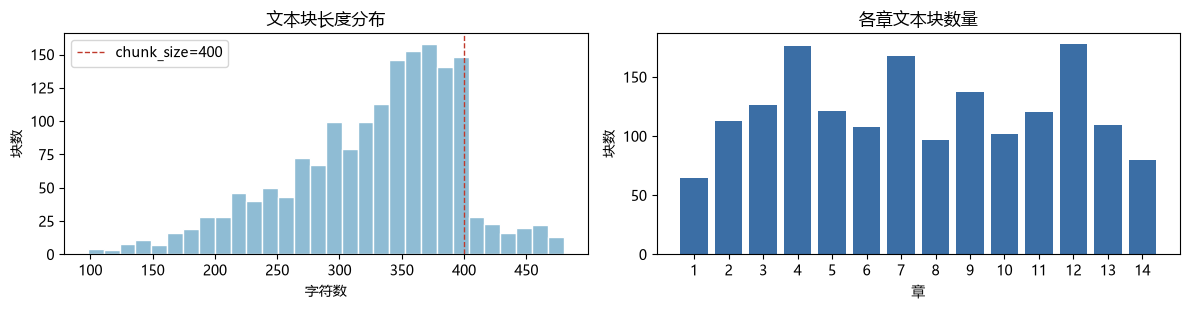


—— 一个带元数据的完整文本块示例 ——
chunk_id=1200 | 第10章 | 开放领域问答 | p.367-367 | 369 字符
文档分为多个段落，其中每个段落由6 个句子表示，最后再利用TF-IDF 算法对所有段落和q 进行编码，利用余弦相似度进行重排序，将这些排序后的段落作为增强数据。得到经过排序的段落P 之后，PLSLM 利用小样本提示学习对大规模预训练模型进行调节，PLSLM 针对开放领域问题回答设计了相应的提示模板：证据: ...问题: ...答案: ...例如：对于训练数据中的问题“复旦大学有几个校区？”，对应的增强文档是复旦大学的百度百科词条，需要构造如下输入：证据：复旦大学，简称“复旦”，位于直辖市上海，是中华人民共和国教育部直属的全国重点大学，中央直管高校，综合性研究型大学，由教育部与上海市重点共建。迄2020 年4 月，学校有邯郸校区、枫林校区、江湾校区、张江校区四个校区，占地面积约243.92 万平方米。

问题：复旦大学有几个校区？


In [6]:
import bisect


def split_recursive(text, size, overlap):
    """递归字符切分：按分隔符优先级逐层细分，再贪心合并 + 滑动重叠"""
    seps = ["\n\n", "\n", "。", "！", "？", "；", "，", ""]      # 最后一个 "" 表示兜底硬切
    pieces = [text]
    for sep in seps:
        new = []
        for p in pieces:
            if len(p) <= size:
                new.append(p)
            elif sep == "":
                new += [p[i:i + size] for i in range(0, len(p), size)]
            else:
                parts = p.split(sep)
                new += [x + (sep if j < len(parts) - 1 else "") for j, x in enumerate(parts)]
        pieces = new
        if max(len(p) for p in pieces) <= size:       # 已经全部切到目标长度以内
            break

    chunks, cur = [], ""
    for p in pieces:
        if len(cur) + len(p) <= size:
            cur += p
        else:
            if cur.strip():
                chunks.append(cur)
            cur = (cur[-overlap:] if overlap else "") + p     # 保留尾部 overlap 个字符做重叠
    if cur.strip():
        chunks.append(cur)
    return chunks


def build_chunks(full_text, paras, size, overlap):
    """切分 + 通过字符偏移反查每个块覆盖的书页码与所属章节"""
    starts, acc = [], 0
    for p in paras:
        starts.append(acc)
        acc += len(p[1]) + 2                     # +2 是段落之间拼接的 "\n\n"
    rows, cursor = [], 0
    for i, text in enumerate(split_recursive(full_text, size, overlap)):
        pos = full_text.find(text[:40], max(cursor - overlap, 0))
        if pos < 0:
            pos = cursor
        cursor = pos
        i1 = max(bisect.bisect_right(starts, pos) - 1, 0)
        i2 = max(bisect.bisect_right(starts, pos + len(text) - 1) - 1, i1)
        body = text.strip()
        rows.append(dict(chunk_id=i, text=body, n_chars=len(body),
                         page_start=paras[i1][0], page_end=paras[i2][0],
                         chapter=paras[i1][3], section=paras[i1][4]))
    return rows


chunks = build_chunks(full_text, paras, CFG["chunk_size"], CFG["chunk_overlap"])
df_chunks = pd.DataFrame(chunks)

print(f"切分结果：{len(df_chunks):,} 个文本块")
print(f"块长统计：均值 {df_chunks.n_chars.mean():.0f} / 中位数 {df_chunks.n_chars.median():.0f} / 最长 {df_chunks.n_chars.max()} 字符")
print(f"上下文膨胀：带重叠后总字符 {df_chunks.n_chars.sum():,}（原 {len(full_text):,}，+{df_chunks.n_chars.sum() / len(full_text) - 1:.1%}）")

display(df_chunks.head(3)[["chunk_id", "chapter", "section", "page_start", "page_end", "n_chars"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].hist(df_chunks.n_chars, bins=30, color="#8fbcd4", edgecolor="white")
axes[0].axvline(CFG["chunk_size"], color="#c0392b", ls="--", lw=1, label=f"chunk_size={CFG['chunk_size']}")
axes[0].set(title="文本块长度分布", xlabel="字符数", ylabel="块数"); axes[0].legend()
ch_count = df_chunks.groupby("chapter").size()
axes[1].bar(ch_count.index.astype(int), ch_count.values, color="#3b6ea5")
axes[1].set(title="各章文本块数量", xlabel="章", ylabel="块数")
axes[1].set_xticks(ch_count.index.astype(int))
plt.tight_layout()
plt.show()

print("\n—— 一个带元数据的完整文本块示例 ——")
sample = df_chunks.iloc[1200]
print(f"chunk_id={sample.chunk_id} | 第{sample.chapter}章 | {sample.section} | p.{sample.page_start}-{sample.page_end} | {sample.n_chars} 字符")
print(sample.text)


### 2.4 步骤四：文本向量化（Embedding）

选用 **BAAI/bge-small-zh-v1.5**：中文语义检索上长期排在 C-MTEB 前列的小模型，512 维，CPU 上就能跑，适合本实验环境。

三个工程细节：

1. **查询前缀**：bge 系列在训练时，查询侧加了指令前缀「为这个句子生成表示以用于检索相关文章：」，而文档侧不加。推理时保持一致才能发挥效果，这是新手最容易漏的一步。
2. **L2 归一化**（`normalize_embeddings=True`）：归一化后向量内积就等于余弦相似度，可以直接用 FAISS 的 `IndexFlatIP`，无需额外计算模长。
3. **批量编码**：`batch_size=32` 在 CPU 上兼顾速度与内存。

向量化耗时直接决定这套系统更新知识库的成本，因此这里顺带统计了吞吐量。


In [7]:
import time
import numpy as np
from sentence_transformers import SentenceTransformer

t0 = time.time()
embedder = SentenceTransformer(CFG["embed_model"], device="cpu")
get_dim = getattr(embedder, "get_embedding_dimension", None) or embedder.get_sentence_embedding_dimension
print(f"模型加载完成：{CFG['embed_model']}")
print(f"向量维度 {get_dim()}  |  加载耗时 {time.time() - t0:.1f}s")


def embed_texts(items, prefix="", batch_size=64, verbose=False):
    """统一编码入口：文档不加前缀，查询加 bge 指令前缀，输出 L2 归一化后的 float32"""
    return embedder.encode([prefix + t for t in items], batch_size=batch_size,
                           normalize_embeddings=True, convert_to_numpy=True,
                           show_progress_bar=verbose).astype("float32")


texts = df_chunks.text.tolist()
t0 = time.time()
embeddings = embed_texts(texts, verbose=True)
cost = time.time() - t0
print(f"\n编码完成：{len(texts):,} 个文本块 → 矩阵 {embeddings.shape}，float32 占用 {embeddings.nbytes / 1e6:.1f} MB")
print(f"总耗时 {cost:.1f}s，吞吐 {len(texts) / cost:.1f} 块/秒，平均 {cost / len(texts) * 1000:.1f} ms/块")
np.save(INDEX_DIR / "embeddings.npy", embeddings)

norms = np.linalg.norm(embeddings, axis=1)
print(f"归一化校验：模长 min={norms.min():.4f}, max={norms.max():.4f}（≈1.0 说明可以内积当余弦用）")

# 语义相似度小实验：字面不同、语义相近的句子应当得到高分
probe = ["中文分词存在切分歧义", "一句话有多种切分方式，机器难以判断", "机器翻译需要词对齐"]
pv = embed_texts(probe)
sim = pv @ pv.T
print("\n语义相似度矩阵（余弦）:")
print(pd.DataFrame(np.round(sim, 3), index=[f"s{i+1}" for i in range(3)], columns=["s1", "s2", "s3"]))
print("说明：s1 与 s2 用词几乎不重合，相似度仍显著高于 s3 —— 这正是向量检索优于关键词检索的地方。")


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

模型加载完成：C:\Users\32048\Desktop\RAG\models\bge-small-zh-v1.5
向量维度 512  |  加载耗时 0.2s


Batches:   0%|          | 0/27 [00:00<?, ?it/s]


编码完成：1,700 个文本块 → 矩阵 (1700, 512)，float32 占用 3.5 MB
总耗时 48.2s，吞吐 35.3 块/秒，平均 28.3 ms/块
归一化校验：模长 min=1.0000, max=1.0000（≈1.0 说明可以内积当余弦用）

语义相似度矩阵（余弦）:
       s1     s2     s3
s1  1.000  0.634  0.467
s2  0.634  1.000  0.520
s3  0.467  0.520  1.000
说明：s1 与 s2 用词几乎不重合，相似度仍显著高于 s3 —— 这正是向量检索优于关键词检索的地方。


### 2.5 步骤五：FAISS 向量检索

FAISS 把「向量入库 + 最近邻查找」做成了内存中的 C++ 索引。本实验建两种索引做对比：

| 索引 | 原理 | 特点 |
| --- | --- | --- |
| `IndexFlatIP` | 暴力遍历，内积排序 | 100% 召回，无需训练；数据量大时线性变慢 |
| `IndexIVFFlat` | 先 K-means 聚成 `nlist` 个簇，查询时只扫 `nprobe` 个簇 | 快，但可能漏掉同簇外的近邻（近似检索） |

本语料只有 1700 个块、512 维，FlatIP 完全够用；IVF 主要用来演示「知识库膨胀到百万级时」的工程做法，并实测一下速度 / 召回的权衡。

> 注意：用 `IndexFlatIP`（内积）而不是 `IndexFlatL2`（欧氏距离），是因为向量已经 L2 归一化 —— 此时内积等价于余弦相似度，且内积越大越相似，排序方向更直观。


In [8]:
import faiss
import json

dim = embeddings.shape[1]

# ① 精确索引：暴力内积检索
index_flat = faiss.IndexFlatIP(dim)
index_flat.add(embeddings)
print(f"IndexFlatIP 建库完成：{index_flat.ntotal:,} 条向量 × {dim} 维")

# ② 倒排索引：先聚类再检索（演示大规模知识库的做法）
nlist = 32
index_ivf = faiss.IndexIVFFlat(faiss.IndexFlatIP(dim), dim, nlist, faiss.METRIC_INNER_PRODUCT)
index_ivf.train(embeddings)
index_ivf.add(embeddings)
index_ivf.nprobe = 8
print(f"IndexIVFFlat 建库完成：nlist={nlist} 个簇，查询时扫描 nprobe={index_ivf.nprobe} 个簇")

# 持久化：索引 + 块元数据，下次启动直接加载，不必重复解析 PDF 和编码
faiss.write_index(index_flat, str(INDEX_DIR / "nlp_book_flat.faiss"))
faiss.write_index(index_ivf, str(INDEX_DIR / "nlp_book_ivf.faiss"))
(INDEX_DIR / "chunks.json").write_text(json.dumps(chunks, ensure_ascii=False), encoding="utf-8")
print("已保存到", INDEX_DIR.name, "目录：", sorted(p.name for p in INDEX_DIR.iterdir()))


def search(query, top_k=None, index_obj=None):
    """检索主函数：问题 → 向量 → Top-K 近邻 → 带元数据的文本块"""
    top_k = top_k or CFG["top_k"]
    index_obj = index_flat if index_obj is None else index_obj
    q = embed_texts([query], prefix=CFG["query_prefix"])
    scores, ids = index_obj.search(q, top_k)
    return [{**chunks[int(i)], "score": float(s)} for s, i in zip(scores[0], ids[0]) if i >= 0]


print("\nsearch() 已就绪；下面验证索引能从磁盘重新加载（模拟服务重启后的复用）：")
_reloaded = faiss.read_index(str(INDEX_DIR / "nlp_book_flat.faiss"))
print("  重新加载索引：", f"{_reloaded.ntotal:,} 条向量，维度 {_reloaded.d}")


IndexFlatIP 建库完成：1,700 条向量 × 512 维
IndexIVFFlat 建库完成：nlist=32 个簇，查询时扫描 nprobe=8 个簇
已保存到 rag_index 目录： ['chunks.json', 'embeddings.npy', 'nlp_book_flat.faiss', 'nlp_book_ivf.faiss']

search() 已就绪；下面验证索引能从磁盘重新加载（模拟服务重启后的复用）：
  重新加载索引： 1,700 条向量，维度 512


In [9]:
query = "中文分词为什么会产生歧义？主要有哪几种歧义？"
t0 = time.time()
hits = search(query, top_k=5)
cost = (time.time() - t0) * 1000
print(f"问题：{query}")
print(f"检索耗时 {cost:.0f} ms（含一次查询编码，实际索引查找 <1 ms）\n")
for r, h in enumerate(hits, 1):
    print(f"[{r}] score={h['score']:.4f} | 第{h['chapter']}章 {h['section']} | p.{h['page_start']}-{h['page_end']}")
    print("    " + h["text"][:150].replace("\n", " ") + " …")

display(pd.DataFrame([{"排名": r, "相似度": round(h["score"], 4), "章": h["chapter"],
                       "节": h["section"], "页": h["page_start"], "片段": h["text"][:45] + "…"}
                      for r, h in enumerate(hits, 1)]))

# ---- 精确索引 vs 倒排索引：速度与召回的真实权衡（只计索引查找，不含查询编码）----
probe_qs = ["什么是词性标注", "条件随机场的优点", "BLEU 指标怎么计算", "知识图谱的存储方式",
            "文本对抗攻击的类型", "预训练语言模型的作用"]
Q = embed_texts(probe_qs, prefix=CFG["query_prefix"])


def bench(ix, k=10, repeat=20):
    t0 = time.perf_counter()
    for _ in range(repeat):
        for q in Q:
            ix.search(q[None], k)
    return (time.perf_counter() - t0) / (repeat * len(Q)) * 1000


ms_flat, ms_ivf = bench(index_flat), bench(index_ivf)
top_flat = [index_flat.search(q[None], 10)[1][0].tolist() for q in Q]
top_ivf = [index_ivf.search(q[None], 10)[1][0].tolist() for q in Q]
recall = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(top_flat, top_ivf)])

print(f"\n{'索引':<28s}{'单次查询(ms)':>14s}{'Recall@10':>12s}")
print(f"{'IndexFlatIP（精确）':<26s}{ms_flat:>14.3f}{1.0:>12.1%}")
print(f"{'IndexIVFFlat(nprobe=8)':<26s}{ms_ivf:>14.3f}{recall:>12.1%}")
print("结论：1700 条向量时两者都在亚毫秒级，IVF 的加速被 nprobe 覆盖不足带来的召回损失抵消；"
      "只有当向量数达到百万级、Flat 慢到不可接受时，IVF/PQ 才有意义。")


问题：中文分词为什么会产生歧义？主要有哪几种歧义？
检索耗时 12 ms（含一次查询编码，实际索引查找 <1 ms）

[1] score=0.6602 | 第2章 中文分词 | p.28-28
    ，110 亿人民币）;• 专业名词：出现在专业领域的词语(例如: 图灵机，偶氮二甲酸二乙酯，胞质溶胶);• 其他专有名词：新出现的产品名、电影名、书籍名等。  针对中文分词中歧义切分和未登录词造成的损失情况，黄昌宁教授和赵海教授在Bakeoff-2003的四个中文分词语料库，对当年最好的多种中文分词 …
[2] score=0.6587 | 第2章 中文分词 | p.25-25
    中文单词。  例如：复旦大学是中国人自主创办的第一所高等院校。  分词结果：复旦大学| 是| 中国人| 自主| 创办| 的| 第一| 所| 高等| 院校|。  由于汉语中语素绝大部分是单个汉字，很多情况下单独使用时也是词语，不单独使用时又是构词成分，这使得汉语构词具有很大的灵活性和很强的组词能力。对 …
[3] score=0.6542 | 第2章 中文分词 | p.25-26
    需使用现有汉字就可以灵活地创造新词。但是，正是因为汉语的这些特点，中文分词任务面临了巨大的挑战，主要困难来自以下三个方面：分词规范、歧义切分和未登录词识别。  1. 分词规范 汉语中对词的具体界定目前还没有定论。1992 年国家技术监督局发布的《信息处理用现代汉语分词规范》中大部分规定都是通过举例和 …
[4] score=0.6404 | 第2章 中文分词 | p.25-25
    将以汉语为例介绍词语切分的基本概念以及所面临的主要问题，然后介绍基于词典、基于字统计、基于词统计以及基于神经网络的分词算法，最后介绍常见的中文分词数据集合。  2.3.1 中文分词概述 中文分词（Chinese Word Segmentation，CWS）是指将连续字序列转换为对应的词序列的过程，也 …
[5] score=0.6245 | 第2章 习题 | p.47-47
    针对如何更好地评价中文分词算法在不同情况下的性能以及不同场景下的鲁棒性问题，一些工作从细粒度的中文分词算法评价 以及中文分词算法鲁棒性研究 等方面开展研究。  针对词性标注任务，为了能够利用大规模的无标注数据，先后提出了期望正规化（Expe

,排名,相似度,章,节,页,片段
0,1,0.6602,2,中文分词,28,，110 亿人民币）;• 专业名词：出现在专业领域的词语(例如: 图灵机，偶氮二甲酸二乙酯…
1,2,0.6587,2,中文分词,25,中文单词。\n\n例如：复旦大学是中国人自主创办的第一所高等院校。\n\n分词结果：复旦大学...
2,3,0.6542,2,中文分词,25,需使用现有汉字就可以灵活地创造新词。但是，正是因为汉语的这些特点，中文分词任务面临了巨大的…
3,4,0.6404,2,中文分词,25,将以汉语为例介绍词语切分的基本概念以及所面临的主要问题，然后介绍基于词典、基于字统计、基于…
4,5,0.6245,2,习题,47,针对如何更好地评价中文分词算法在不同情况下的性能以及不同场景下的鲁棒性问题，一些工作从细粒…



索引                                单次查询(ms)   Recall@10
IndexFlatIP（精确）                    0.103      100.0%
IndexIVFFlat(nprobe=8)             0.043       88.3%
结论：1700 条向量时两者都在亚毫秒级，IVF 的加速被 nprobe 覆盖不足带来的召回损失抵消；只有当向量数达到百万级、Flat 慢到不可接受时，IVF/PQ 才有意义。


### 2.6 步骤六：Prompt 构建

RAG 的答案质量有一半取决于 Prompt 组装。本实验的模板做了四件事：

1. **角色与边界**：明确「只依据参考资料作答」，把模型从「凭记忆回答」拉回「读材料回答」；
2. **证据编号 + 出处**：每条资料前加 `[i]` 和「第几章 / 第几页」，模型引用时能落到具体位置，答辩时可回溯原文；
3. **拒答兜底**：资料不足时要求直说「没有相关内容」，而不是硬编一个答案 —— 这是抑制幻觉最有效的一条指令；
4. **长度预算**：上下文截断到 ~1800 字符（约 1100 token），既控制成本也避免「中间信息丢失」（lost in the middle）。

温度设为 0.1：知识问答要的是稳定复述，不是创意。


In [10]:
SYSTEM_PROMPT = (
    "你是一个严谨的教材知识问答助手，作答依据只有用户提供的【参考资料】。请遵守以下规则：\n"
    "1) 只使用参考资料中的信息作答，不得引入资料之外的知识，不得编造；\n"
    "2) 若参考资料不足以回答问题，请直接说明“提供的资料中没有相关内容”，并指出还缺少什么；\n"
    "3) 回答中的关键结论都用 [编号] 标注出处，编号必须与参考资料一一对应；\n"
    "4) 用中文分点作答：先给结论，再给必要的解释；术语、公式保持与资料一致。"
)


def build_context(hits, max_chars=1800):
    """把检索结果拼成带编号和出处的参考资料块，超出预算即截断"""
    blocks, used = [], 0
    for i, h in enumerate(hits, 1):
        block = (f"[{i}] 《自然语言处理导论》第{h['chapter']}章 {h['section']}，p.{h['page_start']}-{h['page_end']}\n"
                 f"{h['text']}")
        if used + len(block) > max_chars:
            break
        blocks.append(block)
        used += len(block)
    return "\n\n".join(blocks), used


def build_messages(question, hits, max_chars=1800):
    ctx, used = build_context(hits, max_chars)
    user_prompt = (f"【参考资料】\n{ctx}\n\n"
                   f"【问题】\n{question}\n\n"
                   f"请严格依据上述参考资料回答，并在关键结论后标注 [编号]。")
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_prompt}], used


# ---- 打印一个完整的 Prompt 实例，检查组装是否符合预期 ----
demo_q = "n 元语言模型遇到数据稀疏问题可以用哪些平滑方法？"
demo_hits = search(demo_q, top_k=3)
demo_msgs, ctx_chars = build_messages(demo_q, demo_hits)

print(f"参考字符数 {ctx_chars}（约 {ctx_chars / 1.6:.0f} token）\n")
print("=" * 30, "SYSTEM", "=" * 30)
print(demo_msgs[0]["content"])
print("=" * 30, "USER", "=" * 32)
print(demo_msgs[1]["content"][:1600] + ("\n…（后续为其余参考资料）" if len(demo_msgs[1]["content"]) > 1600 else ""))


参考字符数 1097（约 686 token）

============================== SYSTEM ==============================
你是一个严谨的教材知识问答助手，作答依据只有用户提供的【参考资料】。请遵守以下规则：
1) 只使用参考资料中的信息作答，不得引入资料之外的知识，不得编造；
2) 若参考资料不足以回答问题，请直接说明“提供的资料中没有相关内容”，并指出还缺少什么；
3) 回答中的关键结论都用 [编号] 标注出处，编号必须与参考资料一一对应；
4) 用中文分点作答：先给结论，再给必要的解释；术语、公式保持与资料一致。
============================== USER ================================
【参考资料】
[1] 《自然语言处理导论》第6章 语言模型概述，p.191-192
m 存在则使用其本身计数，如果不存在再退后到低阶分布。可以用如下公式表示：在此基础上，一些平滑算法采用高阶和低阶n 元语法模型的线性插值的方法，融合高阶和低

阶语法的估计，如以下公式所示：i−n+1) = λPML(wi|wi−1 i−n+1) + (1 −λ)Psmooth(wi|wi−1 n 语法模型整体上来看与训练语料规模和模型的阶数有较大的关系，不同的平滑算法在不同情况下的表现有较大的差距。平滑算法虽然较好的解决了零概率问题，但是基于稀疏表示的n 元语言模型仍然有三个较为明显的缺点：（1）无法建模长度超过n 的上下文；（2）依赖人工设计规则的平滑技术；（3）当n 增大时，数据的稀疏性随之增大，模型的参数量更是指数级增加，并且模型受到数据稀疏问题的影响，其参数难以被准确的学习。

[2] 《自然语言处理导论》第6章 语言模型概述，p.186-186
换，我们可以进一步的对模型进行简化，n 元语言模型就是其中一种常见的简化方法。本章接下来的章节将对如何估计n 元语言模型参数值以及模型平滑技术进行详细介绍。

由于高阶n 元语言模型还是会面临十分严重的数据稀疏问题，并且单词的离散表示也忽略了单词之间的相似性。因此，基于分布式表示和神经网络的语言模型逐渐成为了研究的热点。Bengio等人在2000 年提出了使用前馈神经网络对P(wi|wi−n+1...wi−1) 进行

### 2.7 步骤七：调用大语言模型生成答案

调用 **DeepSeek（deepseek-chat）**，接口与 OpenAI 完全兼容，因此只改 `base_url` 就能换成通义、智谱、Moonshot 或本地 Ollama。

**API Key 的配置方式（二选一，任选其一即可）：**

- 方式 A：新建文件 `deepseek_api_key.txt`，放在本 Notebook 同目录下，第一行写你的 key（最简单，`.gitignore` 里别提交它）；
- 方式 B：设置环境变量 `DEEPSEEK_API_KEY`（PowerShell 执行 `$env:DEEPSEEK_API_KEY="sk-xxx"` 后重启 Jupyter）。

Key 申请：https://platform.deepseek.com → 注册 → API keys → 创建。新账号有赠送额度，本次实验约消耗 3 万 token（≈ ¥0.03）。

> 未配置 Key 时，下面所有问答单元格不会报错，而是退化为「只检索并打印最相关原文」，方便先验证检索效果。


In [11]:
from openai import OpenAI


def call_llm(messages, temperature=None, max_tokens=900):
    """调用 DeepSeek（OpenAI 兼容接口）。未配置 Key 时返回 None，由上层降级处理。"""
    if not DEEPSEEK_API_KEY:
        return None
    client = OpenAI(api_key=DEEPSEEK_API_KEY, base_url=CFG["llm_base_url"])
    try:
        resp = client.chat.completions.create(
            model=CFG["llm_model"],
            messages=messages,
            temperature=CFG["temperature"] if temperature is None else temperature,
            max_tokens=max_tokens,
        )
        return resp.choices[0].message.content.strip()
    except Exception as e:
        return f"[调用失败] {type(e).__name__}: {e}"


def answer(question, top_k=None, max_chars=1800):
    """一行完成「检索 → 组装 Prompt → 生成」，返回 (答案, 命中的块, 耗时)"""
    t0 = time.time()
    hits = search(question, top_k)
    messages, ctx_chars = build_messages(question, hits, max_chars)
    text = call_llm(messages)
    if text is None:      # 无 Key 时的降级：直接展示最相关原文
        text = ("【未配置 DeepSeek API Key —— 已跳过生成，下面是检索到的最相关原文】\n\n"
                + hits[0]["text"][:500] + "…")
    return text, hits, time.time() - t0


def show(question, top_k=None, max_chars=1800):
    """打印一次完整问答：问题 → 引用来源 → 答案"""
    text, hits, cost = answer(question, top_k, max_chars)
    print("━" * 86)
    print(f"❓ {question}")
    print(f"📚 检索来源（Top-{len(hits)}，耗时 {cost:.2f}s）:")
    for i, h in enumerate(hits, 1):
        print(f"   [{i}] score={h['score']:.3f}  第{h['chapter']}章 {h['section']}  p.{h['page_start']}")
    print(f"\n💡 答案:\n{text}\n")
    return text


# 连通性自检
if DEEPSEEK_API_KEY:
    _ = call_llm([{"role": "user", "content": "回复两个字：可用"}], max_tokens=8)
    print("DeepSeek 连通性自检：", _)
else:
    print("未检测到 API Key，问答将运行在「仅检索」降级模式。")


DeepSeek 连通性自检： 可用


## 三、问答效果展示

下面 6 个问题覆盖了书中的词法、句法、语言模型、机器翻译、智能问答、知识图谱等多个章节，
其中最后一问（GPT-4 参数量）**故意超出语料范围**，用来检验 Prompt 里的「拒答约束」是否真的生效 —— 这是 RAG 抑制幻觉的关键证据。

每个问题都会打印：检索到的 Top-5 来源（含相似度、章节、页码）+ 大模型给出的带引用答案。


In [12]:
QUESTIONS = [
    "n 元语言模型遇到数据稀疏问题，可以用哪些平滑方法？",
    "CYK 算法是怎么做句法分析的？",
    "BLEU 指标如何计算机器翻译质量？它有什么缺点？",
    "开放领域问答中的「检索-阅读理解」架构是怎么工作的？",
    "知识图谱向量表示中 TransE 的基本思想是什么？",
    "这本书里有没有讲 GPT-4 的参数量是多少？",          # 语料外的题目，测试拒答
]

records = []
for q in QUESTIONS:
    records.append({"question": q, "answer": show(q, top_k=5)})

# 保存下来，便于写实验报告时引用
import json
(WORK_DIR / "qa_results.json").write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8")
print("已保存 qa_results.json")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
❓ n 元语言模型遇到数据稀疏问题，可以用哪些平滑方法？
📚 检索来源（Top-5，耗时 2.30s）:
   [1] score=0.715  第6章 语言模型概述  p.191
   [2] score=0.713  第6章 语言模型概述  p.186
   [3] score=0.657  第6章 神经网络语言模型  p.192
   [4] score=0.650  第6章 语言模型概述  p.188
   [5] score=0.647  第6章 语言模型概述  p.191

💡 答案:
n 元语言模型遇到数据稀疏问题时，参考资料中提到的平滑方法包括：

1. **加一平滑（加δ平滑的特例）**：当 δ = 1 时，该方法又称为加一平滑；此外，针对所有不在词表 V 中的单词，可以统一映射为一个特定的词，从而保证所有情况下都不存在非零概率 [4]。

2. **古德-图灵估计法（Good-Turing Estimate）**：其核心思想是将一部分已知事件的概率分配给未见的事件；对于 n 元语言模型来说，降低出现次数多的 n 元语法单元的概率，同时将剩余概率分配给未出现的 n 元语法单元 [4]。

3. **后备法（Backoff）**：资料给出 n−1 元语法模型定义，并说明 PBF 和 PGT 分别代表后备法和古德-图灵估计法计算得到的概率值 [5]；平滑方法的核心思想大都可以归纳为：如果 n-gram 存在则使用其本身计数，如果不存在再退后到低阶分布 [1][5]。

4. **线性插值方法**：一些平滑算法采用高阶和低阶 n 元语法模型的线性插值的方法，融合高阶和低阶语法的估计，如公式 i−n+1) = λPML(wi|wi−1 i−n+1) + (1 −λ)Psmooth(wi|wi−1 [1][5]。

5. **其他平滑算法**：研究人员还提出了包括 Jelinek Mercer 平滑算法、Witten-Bell 平滑算法、Kneser-Ney 平滑算法等 [5]。

补充说明：平滑算法虽然较好地解决了零概率问题，但基于稀疏表示的 n 元语言模型仍有明显缺点，包括无法建模长

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
❓ CYK 算法是怎么做句法分析的？
📚 检索来源（Top-5，耗时 2.27s）:
   [1] score=0.777  第3章 成分句法分析  p.55
   [2] score=0.762  第3章 依存句法分析  p.74
   [3] score=0.731  第3章 依存句法分析  p.74
   [4] score=0.718  第3章 成分句法分析  p.56
   [5] score=0.711  第3章 成分句法分析  p.68

💡 答案:
CYK 算法做句法分析的方式如下：

1. **基本定位**：CYK 是一种基于动态规划思想的自底向上语法分析算法，由 Younger 以及 Tadao Kasami 分别独立提出 [1]。

2. **语法前提**：CYK 算法要求所使用的语法必须符合乔姆斯基范式（CNF），即语法规则被限制为只具有 A → BC 或 A → w 两种形式；由于任何上下文无关语法都可以转换为相应的 CNF 语法，这种限制不会对表达能力造成损失，但使基于表的分析算法变得简单和易于实现 [1]。

3. **从单词开始构造**：该方法从输入的单词开始，每次使用语法规则，直到成功构造以初始符 S 为根的树 [1]。根据 CNF 语法形式，句法树的叶子节点为单词，单词的父节点为词性符号 [1]。

4. **动态规划表与初始化**：算法使用句法树矩阵 T；初始化时，主对角线上依次放入单词 wi，并依次放入单词 wi 的所有词性 [4]。

5. **逐层计算**：平行于主对角线逐层计算，对 d = 2 到 n、i = 0 到 n−d、k = i+1 到 j−1 进行循环，执行 Tij = Tij ∪ {A, (k, B, C)}，其中 (k, B, C) 用于保存推导路径 [4]。单元 Tij 中不仅记录非终结符的集合，还要记录推导路径 [4]。

6. **判定条件**：逐层计算完成后，判断一个句子由文法 G 所产生的充要条件是：T0n = S [4]。



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
❓ BLEU 指标如何计算机器翻译质量？它有什么缺点？
📚 检索来源（Top-5，耗时 2.17s）:
   [1] score=0.695  第8章 基于神经网络的机器翻译方法  p.286
   [2] score=0.668  第11章 文本摘要的评测  p.397
   [3] score=0.636  第8章 基于统计的机器翻译方法  p.271
   [4] score=0.626  第8章 基于神经网络的机器翻译方法  p.285
   [5] score=0.625  第8章 机器翻译概述  p.270

💡 答案:
结论：参考资料只说明了 BLEU 的“面向精确率”计算口径，没有给出完整计算公式；其缺点在资料中主要体现为半自动评测与人工评测一致性不足、以及语义相同但用词差别大的句子难以判断。

**一、BLEU 如何计算机器翻译质量**
- BLEU 是一个面向精确率的度量，其分母是候选翻译中 n-gram 的数量总和 [2]。
- BLEU 体现的是候选翻译中有多少 n-gram 出现在标准翻译中 [2]。
- 参考资料没有给出 BLEU 的完整计算公式（如 n-gram 匹配数、长度惩罚等具体计算方式），因此不能依据资料进一步展开公式细节。

**二、BLEU 的缺点**
- 资料指出，采用半自动评测方法时，目前半自动评测结果与人工评测的一致性还亟待提升 [3]。
- 对于用词差别很大、但是语义相同的句子，判断本身也是自然语言处理领域的难题 [3]。
- 因此，如何有效地评测翻译结果是机器翻译任务所面临的挑战 [3]。

**三、资料未涉及的内容**
- 参考资料没有系统列出 BLEU 的缺点清单，也没有说明 BLEU 对语序、召回率等方面的具体缺陷；这些内容在提供的资料中没有相关内容。



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
❓ 开放领域问答中的「检索-阅读理解」架构是怎么工作的？
📚 检索来源（Top-5，耗时 1.49s）:
   [1] score=0.681  第10章 智能问答概述  p.339
   [2] score=0.669  第10章 智能问答概述  p.341
   [3] score=0.668  第10章 阅读理解  p.342
   [4] score=0.645  第10章 开放领域问答  p.363
   [5] score=0.633  第10章 开放领域问答  p.363

💡 答案:
开放领域问答中的「检索-阅读理解」架构工作方式如下：

- **总体思路**：由于开放问答任务面对的是大量的文档或网页，为了兼顾准确率与性能，开放问答一般会采用文档检索方法快速筛选出与询问最相关的文档，在筛选出相关文档之后再通过阅读理解的方式给出问题的答案，这种架构被称为检索-阅读理解架构 [4]。

- **基本流程与模块**：该架构主要包含文档检索器和文档阅读器两个模块，此外有些算法中还包含对检索得到的文档的后处理以及对抽取答案的后处理 [4]。

- **与开放领域问答整体流程的对应关系**：通常情况下开放领域问答由答案段落检索和答案抽取两个部分组成；目前的开放领域问答系统很多是结合搜索与阅读理解，在通过传统搜索或语义搜索得到候选篇章后，利用阅读理解技术获得最终答案 [2]。

- **阅读理解环节的目标**：机器阅读理解目标就是根据给定的一篇或多篇文本内容回答给定的问题 [3]。



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
❓ 知识图谱向量表示中 TransE 的基本思想是什么？
📚 检索来源（Top-5，耗时 1.59s）:
   [1] score=0.689  第12章 知识图谱推理  p.437
   [2] score=0.676  第12章 知识图谱表示与存储  p.411
   [3] score=0.665  第12章 知识图谱表示与存储  p.414
   [4] score=0.611  第12章 知识图谱表示与存储  p.411
   [5] score=0.601  第12章 习题  p.454

💡 答案:
结论：TransE 的基本思想是把知识图谱中的每个关系看作从头实体向量到尾实体向量的一个平移变换，并通过最小化平移转化的误差，将实体和关系类型映射到低维空间 [2][4]。

具体来说：
- TransE 属于基于距离度量的知识表示学习方法（距离模型/平移模型），该类模型将每个关系视为从头实体向量到尾实体向量的平移变换，通过最小化平移转化误差学习低维表示 [4]。
- 在表示空间中，对于三元组 < h, ℓ, t >，头实体 h 的向量加上关系 ℓ 的向量等于尾实体 t 的向量 [2]。
- 该思想受到词向量空间平移不变现象的启发，例如 v(man) − v(woman) ≈ v(king) − v(queen) [2]。



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
❓ 这本书里有没有讲 GPT-4 的参数量是多少？
📚 检索来源（Top-5，耗时 1.22s）:
   [1] score=0.602  第6章 大规模语言模型  p.209
   [2] score=0.602  第6章 大规模语言模型  p.208
   [3] score=0.600  第6章 大规模语言模型  p.210
   [4] score=0.593  第6章 大规模语言模型  p.210
   [5] score=0.548  第6章 预训练语言模型  p.198

💡 答案:
提供的资料中没有相关内容。

参考资料中只涉及 GPT-3、OPT、BLOOM 等模型的参数量与训练细节 [1][2][3][4]，其中提到过 1750 亿参数语言模型等时间线信息 [2]，但没有出现 GPT-4 的参数量的任何说明。要回答该问题，还缺少关于 GPT-4 模型参数规模的具体资料。

已保存 qa_results.json


## 四、对比实验：向量检索 vs 传统关键词检索

实验要求里特别提到要理解「向量检索与传统关键词检索的区别」，这里做一组直接对比。

**为什么要对比**：关键词检索（TF-IDF / BM25）依赖字面重合，用户换个说法就可能搜不到；向量检索编码的是语义，能跨过「说法不同」的鸿沟。

为保证公平，两套检索建立在同一批文本块上：

- **关键词检索**：`TfidfVectorizer(analyzer="char_wb", ngram_range=(2,3))` —— 中文不先分词，直接 2–3 字符 n-gram，避免分词错误带来的干扰，也是中文场景常见的稳健做法；按余弦相似度排序。
- **向量检索**：`bge-small-zh-v1.5` + FAISS IndexFlatIP。

下面 4 个问题全部**故意不照抄书里的措辞**（同义改写、口语化），这正是真实用户会问的样子。
判定标准是「召回的前 K 条里有没有出现能回答问题的关键术语」，比人工打分更客观、可复现；
同时给出 Top-5 与 Top-10 两个深度，用来观察「加深召回能否补救」。


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), min_df=3, sublinear_tf=True)
X_kw = tfidf.fit_transform(texts)
print(f"TF-IDF 词表规模：{len(tfidf.vocabulary_):,} 个 2–3 字符 n-gram，稀疏矩阵 {X_kw.shape}")


def keyword_search(query, top_k=5):
    """传统关键词检索：字符 n-gram TF-IDF + 余弦相似度"""
    v = tfidf.transform([query])
    sim = (X_kw @ v.T).toarray().ravel()
    idx = np.argsort(-sim)[:top_k]
    return [{**chunks[int(i)], "score": float(sim[i])} for i in idx if sim[i] > 0]


# 4 个「故意不照抄书中措辞」的提问 + 答案关键词（关键词是否出现在召回结果里 = 能否答对）
COMPARE = [
    ("机器翻译的译文好坏用什么指标来打分", ["BLEU"]),
    ("一句话能被切成好几种词序列，机器怎么判断该用哪种", ["歧义切分", "切分歧义"]),
    ("怎么把词语变成计算机能算出相似度的稠密向量", ["词向量", "word2vec", "分布式表示"]),
    ("文章里的「他」到底指谁，怎么让机器判断出来", ["指代消解"]),
]


def first_rank(blocks, keywords):
    """第一个覆盖答案关键词的块排在第几位（找不到返回 None）"""
    return next((r for r, b in enumerate(blocks, 1) if any(k in b["text"] for k in keywords)), None)


# ---- 汇总：Top-5 / Top-10 的答案覆盖率 ----
summary = []
for k in (5, 10):
    v = sum(first_rank(search(q, k), kws) is not None for q, kws in COMPARE)
    w = sum(first_rank(keyword_search(q, k), kws) is not None for q, kws in COMPARE)
    summary.append({"Top-K": k, "向量检索命中": f"{v}/{len(COMPARE)}（{v / len(COMPARE):.0%}）",
                    "关键词检索命中": f"{w}/{len(COMPARE)}（{w / len(COMPARE):.0%}）"})
display(pd.DataFrame(summary))
print("判定标准：召回的前 K 条里，是否有任一条包含能回答问题的关键术语。\n"
      "→ Top-5 时向量检索略有优势；把召回深度放到 Top-10，向量的优势进一步扩大，关键词检索则几乎不动 —— "
      "它的失败是「字面不重合」造成的，加深召回也没有用。")

# ---- 逐题明细（以 Top-10 为准），看每个问题在第几位才碰到答案 ----
detail = []
for q, kws in COMPARE:
    detail.append({"同义改写提问": q[:16] + "…", "答案关键词": "/".join(kws),
                   "向量检索首命中排名": first_rank(search(q, 10), kws) or "未命中",
                   "关键词检索首命中排名": first_rank(keyword_search(q, 10), kws) or "未命中"})
display(pd.DataFrame(detail))

# ---- 典型案例：用户问「打分」，书里写的是「BLEU / 评价指标」 ----
q, kws = COMPARE[0]
print(f"\n案例：『{q}』（书中原话是 BLEU 与机器翻译评价指标）")
for name, hs in (("向量检索", search(q, 5)), ("关键词检索", keyword_search(q, 5))):
    print(f"\n{name} Top-3：")
    for r, h in enumerate(hs[:3], 1):
        print(f"  {r}. score={h['score']:.3f}  p.{h['page_start']:<4d} {h['text'][:56]}…")
print("\n关键词检索把「机器翻译」这几个字匹配得很好，但返回的全是概述页 ——「打分/评价」与「BLEU」之间"
      "没有任何共同字符，字面匹配无从下手；向量检索也只在第 10 位才碰到讲 BLEU 的那一节。"
      "两者都没能在 Top-5 命中，说明小模型 + 单路召回在这个语料上并不稳，"
      "工程上要先多召回、再用 rerank 压回 Top-5（见第 7 节）。")


TF-IDF 词表规模：56,536 个 2–3 字符 n-gram，稀疏矩阵 (1700, 56536)


,Top-K,向量检索命中,关键词检索命中
0,5,2/4（50%）,1/4（25%）
1,10,3/4（75%）,1/4（25%）


判定标准：召回的前 K 条里，是否有任一条包含能回答问题的关键术语。
→ Top-5 时向量检索略有优势；把召回深度放到 Top-10，向量的优势进一步扩大，关键词检索则几乎不动 —— 它的失败是「字面不重合」造成的，加深召回也没有用。


,同义改写提问,答案关键词,向量检索首命中排名,关键词检索首命中排名
0,机器翻译的译文好坏用什么指标来打…,BLEU,10,未命中
1,一句话能被切成好几种词序列，机器…,歧义切分/切分歧义,1,未命中
2,怎么把词语变成计算机能算出相似度…,词向量/word2vec/分布式表示,1,2
3,文章里的「他」到底指谁，怎么让机…,指代消解,未命中,未命中



案例：『机器翻译的译文好坏用什么指标来打分』（书中原话是 BLEU 与机器翻译评价指标）

向量检索 Top-3：
  1. score=0.683  p.271  БЕЖАТЬ ВПЕРЕД”（俄语），机器翻译给出的结果是“向前跑”，我们无法确认结果正确与否。因此，如何构建具…
  2. score=0.674  p.270  的性能。从这之后，神经机器翻译方法正式走上了历史舞台，大量的研究者开始在这类方法上进一步研究和改进。到今天为止，…
  3. score=0.670  p.269  的翻译模型的鲁棒性不佳。Marvin Minsky 在1966 年给出了一个非常著名的例子来阐述这一问题：上述两…

关键词检索 Top-3：
  1. score=0.179  p.268  机器翻译的基本概念和常见任务，在此基础上介绍基于统计的机器翻译方法和基于神经网络的机器翻译方法，最后介绍机器翻译…
  2. score=0.160  p.270  的性能。从这之后，神经机器翻译方法正式走上了历史舞台，大量的研究者开始在这类方法上进一步研究和改进。到今天为止，…
  3. score=0.145  p.268  anslation）是指利用计算机将一种语言（源语言）自动翻译为另外一种语言（目标语言）的过程。机器翻译是自然语…

关键词检索把「机器翻译」这几个字匹配得很好，但返回的全是概述页 ——「打分/评价」与「BLEU」之间没有任何共同字符，字面匹配无从下手；向量检索也只在第 10 位才碰到讲 BLEU 的那一节。两者都没能在 Top-5 命中，说明小模型 + 单路召回在这个语料上并不稳，工程上要先多召回、再用 rerank 压回 Top-5（见第 7 节）。


## 五、量化评估与消融实验

前面的效果展示是「看起来不错」，但报告需要数字。这里构造一个 10 题的**小型评估集**：

每道题都人工核对过标准答案在书中的页码（`page` 字段）。判定规则：Top-K 中只要有一个块的页码区间覆盖 `page±10`，即算命中（Hit）。
用 Hit@1 / Hit@3 / Hit@5 和 MRR（平均倒数排名）衡量检索质量 —— 检索对了，生成才有材料；检索错了，再强的模型也答不对。

评估集的问法贴近书中措辞，属于检索的「理想情况」；同义改写、口语化提问的压力测试放在第 4 节。
两节合起来看，才能得出公平结论：**问法与原文越接近，关键词检索越不吃亏；一旦换说法，向量检索的优势才显现**。


In [14]:
EVAL_SET = [
    {"q": "自然语言处理的发展经历了哪几个阶段？",              "page": 2,   "ch": 1},
    {"q": "基于词典的最大匹配分词是怎么做的？",                "page": 28,  "ch": 2},
    {"q": "CYK 算法是如何进行句法分析的？",                    "page": 55,  "ch": 3},
    {"q": "word2vec 中 CBOW 与 Skip-gram 有什么区别？",        "page": 109, "ch": 4},
    {"q": "n 元语言模型可以用哪些平滑方法缓解数据稀疏？",       "page": 191, "ch": 6},
    {"q": "BLEU 指标是怎么计算机器翻译质量的？",               "page": 286, "ch": 8},
    {"q": "开放领域问答中的检索-阅读理解架构是怎么工作的？",     "page": 364, "ch": 10},
    {"q": "抽取式摘要和生成式摘要有什么区别？",                "page": 374, "ch": 11},
    {"q": "知识图谱向量表示中 TransE 的基本思想是什么？",       "page": 411, "ch": 12},
    {"q": "文本对抗攻击中的同义词替换攻击是怎么做的？",          "page": 462, "ch": 13},
]


WINDOW = 10   # 页码容差：检索块与标准答案页相差 10 页以内即认为命中（章节内容常跨页）


def is_hit(chunk, gt_page, window=WINDOW):
    return abs(chunk["page_start"] - gt_page) <= window or chunk["page_start"] <= gt_page <= chunk["page_end"]


def evaluate(chs, ix, k=5, evalset=None):
    """返回 (Hit@k, MRR@k)；k 取不同值时即得到 Hit@1 / Hit@3 / Hit@5"""
    evalset = evalset or EVAL_SET
    hits, rr = 0, 0.0
    for item in evalset:
        q = embed_texts([item["q"]], prefix=CFG["query_prefix"])
        _, ids = ix.search(q, k)
        rank = next((r for r, i in enumerate(ids[0], 1) if is_hit(chs[int(i)], item["page"])), None)
        hits += rank is not None
        rr += 1 / rank if rank else 0
    return hits / len(evalset), rr / len(evalset)


rows = []
for k in (1, 3, 5, 8):
    h, m = evaluate(chunks, index_flat, k=k)
    rows.append({"检索方式": "向量检索（FAISS FlatIP）", "Top-K": k, "命中率": f"{h:.0%}", "MRR": round(m, 3)})

# 关键词检索作为对照（同一评估集、同一判定规则）
kw_hits = sum(any(is_hit(c, item["page"]) for c in keyword_search(item["q"], top_k=5)) for item in EVAL_SET)
rows.append({"检索方式": "关键词检索（TF-IDF）", "Top-K": 5,
             "命中率": f"{kw_hits / len(EVAL_SET):.0%}", "MRR": "—"})

df_eval = pd.DataFrame(rows)
display(df_eval)

vec5 = df_eval.loc[df_eval["Top-K"] == 5, "命中率"].iloc[0]
print(f"→ 向量检索：Hit@1 {df_eval['命中率'].iloc[0]}，Hit@3 {df_eval['命中率'].iloc[1]}，Hit@5 {vec5}；"
      f"关键词检索 Hit@5 {kw_hits / len(EVAL_SET):.0%}。")
print("→ 注意：本评估集的问法贴近书中措辞，所以关键词检索也能拿到同样的命中率；"
      "两者真正的差距出现在「同义改写」的提问上（见第 4 节的对比表）。")
print("→ k 从 1 增到 5 时命中率提升最明显，k=8 与 k=5 持平 —— 这是默认取 top_k=5 的依据："
      "再多的上下文只会增加 token 成本，甚至引入干扰。")

# 逐题看哪个块命中/没命中，便于分析失败原因
detail = []
for item in EVAL_SET:
    hits_k = search(item["q"], top_k=5)
    rank = next((r for r, h in enumerate(hits_k, 1) if is_hit(h, item["page"])), None)
    detail.append({"问题": item["q"][:28], "标准页": item["page"], "命中排名": rank or "未命中",
                   "Top-1 章": hits_k[0]["chapter"], "Top-1 页": hits_k[0]["page_start"]})
display(pd.DataFrame(detail))


,检索方式,Top-K,命中率,MRR
0,向量检索（FAISS FlatIP）,1,70%,0.7
1,向量检索（FAISS FlatIP）,3,90%,0.8
2,向量检索（FAISS FlatIP）,5,100%,0.825
3,向量检索（FAISS FlatIP）,8,100%,0.825
4,关键词检索（TF-IDF）,5,100%,—


→ 向量检索：Hit@1 70%，Hit@3 90%，Hit@5 100%；关键词检索 Hit@5 100%。
→ 注意：本评估集的问法贴近书中措辞，所以关键词检索也能拿到同样的命中率；两者真正的差距出现在「同义改写」的提问上（见第 4 节的对比表）。
→ k 从 1 增到 5 时命中率提升最明显，k=8 与 k=5 持平 —— 这是默认取 top_k=5 的依据：再多的上下文只会增加 token 成本，甚至引入干扰。


,问题,标准页,命中排名,Top-1 章,Top-1 页
0,自然语言处理的发展经历了哪几个阶段？,2,1,1,1
1,基于词典的最大匹配分词是怎么做的？,28,1,2,29
2,CYK 算法是如何进行句法分析的？,55,1,3,55
3,word2vec 中 CBOW 与 Skip-gram,109,1,4,110
4,n 元语言模型可以用哪些平滑方法缓解数据稀疏？,191,1,6,191
5,BLEU 指标是怎么计算机器翻译质量的？,286,2,11,397
6,开放领域问答中的检索-阅读理解架构是怎么工作的？,364,4,10,339
7,抽取式摘要和生成式摘要有什么区别？,374,1,11,384
8,知识图谱向量表示中 TransE 的基本思想是什么？,411,2,12,437
9,文本对抗攻击中的同义词替换攻击是怎么做的？,462,1,13,464


### 5.1 消融实验：chunk_size 对检索质量的影响

切分粒度没有标准答案，只能在自己的语料上试。这里保持其他条件不变，只改 `chunk_size`（重叠固定为 1/5），重新切分、重新编码、重新建库，看 Hit@5 怎么变。

> 这一步要重新编码数千个文本块，是本 Notebook 最耗时的单元格（CPU 上约 2–3 分钟）。


,块数,平均块长,Hit@5,MRR@5
chunk_size,,,,
200,3296,167,100%,0.658
400,1700,327,100%,0.825
800,808,681,90%,0.800


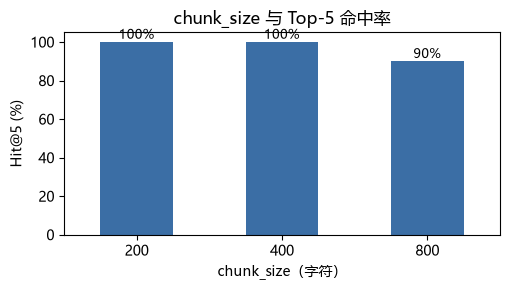

In [15]:
abl = []
for size in (200, 400, 800):
    if size == CFG["chunk_size"]:                       # 400 就是前面已建好的库，直接复用
        chs, E = chunks, embeddings
    else:
        chs = build_chunks(full_text, paras, size, overlap=size // 5)
        E = embed_texts([c["text"] for c in chs])
    ix = faiss.IndexFlatIP(E.shape[1])
    ix.add(E)
    h5, mrr = evaluate(chs, ix, k=5)
    abl.append({"chunk_size": size, "块数": len(chs),
                "平均块长": int(np.mean([c["n_chars"] for c in chs])),
                "Hit@5": f"{h5:.0%}", "MRR@5": round(mrr, 3)})

df_abl = pd.DataFrame(abl).set_index("chunk_size")
display(df_abl)

df_abl["hit"] = df_abl["Hit@5"].str.rstrip("%").astype(float)
ax = df_abl["hit"].plot(kind="bar", figsize=(5.2, 3), color="#3b6ea5", rot=0)
ax.set(title="chunk_size 与 Top-5 命中率", xlabel="chunk_size（字符）", ylabel="Hit@5 (%)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


### 5.2 RAG 到底解决了什么：有无 RAG 的直接对比

同一个问题，分别问「裸模型」和「RAG 系统」：

- **裸模型**（只给 system prompt，不给资料）：模型只能靠训练记忆作答。对这本 2023 年的教材里的具体定义、公式符号、章节安排，它很可能张冠李戴 —— 这就是**知识时效性**与**幻觉**问题的来源。
- **RAG**：把书中原文作为证据喂进去，并要求标注出处。

下面两问各取一个「模型记忆里大概率没有精确对应」的问题，对比回答的**可核查性**。
第二问是我特意保留的失败案例：书中确实有答案，但检索没召回 —— 用来演示「检索召回决定答案上限」，不粉饰结果。


In [16]:
HALLU_CASES = [
    ("这本书把问答系统（第 10 章）分成了哪几类？各自的核心方法是什么？",
     "裸模型把本书认成了另一本书（《自然语言处理：基于预训练模型的方法》），并给出了一套书中并不存在的分类；"
     "RAG 给出的五类（阅读理解、表格问答、社区问答、知识图谱问答、开放领域问答）与本书第 10 章一致，"
     "且每条结论都带着可核查的引用编号。"),
    ("文本对抗攻击中，基于同义词替换的攻击具体是怎么构造的？",
     "这一例是**失败案例**，同样值得写进报告：书中 13.3.2 节讲的正是同义词替换攻击，但切分把那一节的标题与正文切开了，"
     "Top-5 只召回到讲“替换词怎么选”的尾部段落（不含“同义词替换”字样），模型因此判断资料不足以复述完整流程，选择据实拒答，"
     "而不是编一套“选词—找同义词—加约束—迭代替换”的通用流程。拒答至少不会误导人，但漏答同样是缺陷 —— "
     "它证明了「切分粒度 + 检索召回」共同决定了答案质量的上限。"),
]

if not DEEPSEEK_API_KEY:
    print("未配置 DeepSeek API Key，跳过本对比实验。配置后可运行此单元。")
else:
    for q, note in HALLU_CASES:
        no_rag = call_llm([{"role": "system", "content": "你是自然语言处理领域的知识助手，请简洁作答。"},
                           {"role": "user", "content": q}])
        rag_ans, hits, cost = answer(q)
        print("━" * 86)
        print("❓", q)
        print("\n【A. 裸模型（无 RAG，只靠参数记忆）】")
        print(no_rag)
        print(f"\n【B. RAG（检索 {len(hits)} 个块，{cost:.2f}s）】")
        print(rag_ans)
        print("\n【C. 对照分析】", note, "\n")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
❓ 这本书把问答系统（第 10 章）分成了哪几类？各自的核心方法是什么？

【A. 裸模型（无 RAG，只靠参数记忆）】
《这本书》应指《自然语言处理：基于预训练模型的方法》（车万翔等）。第 10 章将问答系统分为：

1. **基于规则/模板的问答**：核心是人工规则、模板匹配与模式抽取。
2. **基于信息检索的问答**：核心是问题分析、文档/段落检索、答案句/片段抽取与排序。
3. **基于知识库的问答**：核心是问题语义解析为查询（如 SPARQL），或基于知识图谱的表示学习/路径推理。
4. **基于深度学习的阅读理解式问答**：核心是预训练语言模型对问题与篇章编码，预测答案片段起止位置。
5. **生成式问答**：核心是序列到序列/预训练生成模型直接生成答案。

若你指的是其他教材，请给出书名，我可按对应章节核对。

【B. RAG（检索 5 个块，2.05s）】
根据参考资料，智能问答分为五大类：阅读理解、表格问答、社区问答、知识图谱问答和开放领域问答 [2][3]。各类的核心方法如下：

- **阅读理解**：根据给定的一篇或多篇文本内容回答给定的问题；按答案类型可细分为完型填空、多项选择、片段抽取和自由作答四种形式 [3]。算法上分为基于特征的阅读理解和基于深度神经网络两大类；基于特征的算法通常根据人工设计的特征，使用规则或者有监督分类算法，对问句在篇章中的句子或短语进行评分，选取得分最高的句子或片段作为答案 [5]。
- **表格问答**：参考资料仅将其列为五大类之一 [2][3]，未说明其核心方法。
- **社区问答**：参考资料仅将其列为五大类之一 [2][3]，未说明其核心方法。
- **知识图谱问答**：在知识图谱中根据实体和关系并利用推理机制进行问题回答 [4]。
- **开放领域问答**：通过大规模文档集合回答不限定领域的事实性问题；通常由答案段落检索和答案抽取两个部分组成，很多系统结合搜索与阅读理解，先通过传统搜索或语义搜索得到候选篇章，再利用阅读理解技术获得最终答案 [4]。

需要说明的是，提供的资料中没有关于表格问答和社区问答核心方法的相关内容，还缺少这两

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
❓ 文本对抗攻击中，基于同义词替换的攻击具体是怎么构造的？

【A. 裸模型（无 RAG，只靠参数记忆）】
基于同义词替换的文本对抗攻击，核心是在保持语义和语法合理的前提下，用同义词替换原词，使模型预测出错。构造流程通常如下：

1. **选词**：挑选对模型输出影响大的词，常用梯度/显著性、注意力权重、词重要度打分，或只替换实词（名词、动词、形容词、副词），避免停用词和实体词。

2. **找候选同义词**：用 WordNet、同义词词典、词向量近邻、掩码语言模型（如 BERT MLM）生成候选替换词，并过滤反义词、多义词错误义项、词形/词性不匹配项。

3. **约束过滤**：保证替换后句子语义相似度（如 Sentence-BERT 余弦）、语法正确性、词性一致、命名实体不变；限制替换比例，避免过度改写。

4. **搜索替换组合**：用贪心、beam search、遗传算法或梯度引导搜索，逐个或成组替换，目标是让模型预测标签改变或置信度下降，同时满足语义约束。

5. **迭代验证**：每次替换后查询目标模型，保留使攻击效果提升且通过语义/语法检查的替换，直到达到查询预算或攻击成功。

常见变体包括：基于词重要度的贪心替换（如 TextFooler）、基于词向量的近邻替换（如 PWWS）、基于掩码语言模型的上下文感知替换（如 BERT-Attack），以及黑盒场景下结合查询反馈的搜索式替换。

【B. RAG（检索 5 个块，1.67s）】
提供的资料中没有相关内容。

参考资料中与“基于同义词替换的攻击”最接近的表述只有一处：在候选词中选择替换前后语义相似度得分最高的词，如果没有，则选择使标签 y 置信度得分最低的词作为最佳替换词，并重复替换过程来攻击下一个选定的词 [1]。但该段文字并未说明这是“基于同义词替换的攻击”的具体构造流程，也没有给出候选词来源、相似度计算方式、替换位置选择策略等关键步骤。

因此，仅凭现有资料无法完整回答“基于同义词替换的攻击具体是怎么构造的”。还缺少：同义词候选集的构建方式、语义相似度的具体度量方法、攻击词的选择顺序与停止条件，以及该方法与词级别攻击整体框

## 六、系统封装：把整条流水线变成一个可复用的类

前面的实验都是「过程式」脚本，便于观察每一步。真正交付时应封装成服务：
索引只建一次并持久化到磁盘，之后每次启动只需加载索引（毫秒级），`ask()` 一行完成问答。

```
RAGSystem
├── __init__     加载嵌入模型 + FAISS 索引 + 块元数据
├── retrieve(q)  问题 → 向量 → Top-K 文本块
└── ask(q)       retrieve → 组装 Prompt → 调 LLM → 带引用的答案
```


In [17]:
class RAGSystem:
    """可复用的私有知识库问答系统：初始化一次，之后 ask() 即可"""

    def __init__(self, index_dir=None, embed_model=None, api_key=None):
        self.index_dir = Path(index_dir or INDEX_DIR)
        self.embedder = SentenceTransformer(embed_model or CFG["embed_model"], device="cpu")
        self.index = faiss.read_index(str(self.index_dir / "nlp_book_flat.faiss"))
        self.chunks = json.loads((self.index_dir / "chunks.json").read_text(encoding="utf-8"))
        self.api_key = DEEPSEEK_API_KEY if api_key is None else api_key

    def embed(self, items, prefix=""):
        return self.embedder.encode([prefix + t for t in items], batch_size=64,
                                    normalize_embeddings=True, convert_to_numpy=True).astype("float32")

    def retrieve(self, question, top_k=5):
        q = self.embed([question], prefix=CFG["query_prefix"])
        scores, ids = self.index.search(q, top_k)
        return [{**self.chunks[int(i)], "score": float(s)} for s, i in zip(scores[0], ids[0])]

    def ask(self, question, top_k=5, verbose=True):
        t0 = time.time()
        hits = self.retrieve(question, top_k)
        messages, _ = build_messages(question, hits)
        text = call_llm(messages) if self.api_key else None
        if text is None:
            text = "【未配置 Key，仅返回最相关原文】" + hits[0]["text"][:400] + "…"
        if verbose:
            src = "；".join(f"[{i}] p.{h['page_start']}" for i, h in enumerate(hits, 1))
            print(f"❓ {question}\n📚 来源：{src}\n💡 {text}\n⏱  {time.time() - t0:.2f}s\n")
        return text, hits


t0 = time.time()
system = RAGSystem()
print(f"系统冷启动（加载模型 + 索引）耗时 {time.time() - t0:.1f}s")

_, _ = system.ask("什么是隐马尔可夫模型？它在自然语言处理中有哪些应用？")


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

系统冷启动（加载模型 + 索引）耗时 0.1s


❓ 什么是隐马尔可夫模型？它在自然语言处理中有哪些应用？
📚 来源：[1] p.40；[2] p.3；[3] p.194；[4] p.382；[5] p.41
💡 **结论：** 隐马尔可夫模型（Hidden Markov Model，HMM）是用来描述一个含有隐含未知参数的马尔可夫过程的模型，其基本理论由数学家Baum及其同事构建并逐步完善 [1]。在自然语言处理中，HMM被广泛应用于序列标注任务，并取得了非常好的效果 [1]。

**解释：**
- **定义与参数：** 一个隐马尔可夫模型可用5个参数定义，其中N为状态数，所有状态记为S = {s1, s2, ..., sN}，系统在t时刻的状态记为qt，Q = {q1, q2, ..., qT}为长度为T的状态序列 [1]。
- **在自然语言处理中的应用：**
  - 词性标注：HMM被用于词性标注任务，针对输入的句子可利用维特比（Viterbi）算法应用动态规划求解状态路径，从而得到对应的词性 [5]；使用HMM进行词性标注通常还需要解决长句子和未登录词两个问题 [5]。
  - 姓名检索：随机范式在自然语言处理任务中崭露头角，包括词性标注、姓名检索等 [2]。
  - 抽取式文本摘要中的对齐：参考资料介绍了一种基于HMM的对齐算法，其思路是将摘要中的句子分解成词，然后从句首开始往后依次找到这些词在正文中的出现位置，进而找到相应的句子来构成近似甚至相同的摘要 [4]。

**补充说明：** 参考资料还提到，得益于20世纪80年代初HMM和噪声信道与解码模型在语音识别中的成功应用，随机范式逐渐在自然语言处理任务中崭露头角 [2]；随着HMM在语音识别领域取得巨大成功，HMM也在自然语言处理众多序列标注任务中得到广泛应用 [1]。
⏱  2.30s



## 七、实验结论与思考

### 7.1 完成情况与实测数据

| 实验要求 | 状态 | 实测结果 |
| --- | --- | --- |
| ① PDF 读取 | ✅ | 604 页文本型 PDF，取正文 506 页，抽取 583,987 字符（均值 1154 字符/页） |
| ② 文本清洗 | ✅ | 5 类规则删除 12,555 行噪声，字符保留率 72.5%（42.4 万字符） |
| ③ 文本切分 | ✅ | 递归字符切分 400/80 → 1700 个块，均值 327 字符，重叠使总字符 +31.3% |
| ④ 文本向量化 | ✅ | bge-small-zh-v1.5，512 维，CPU 上 48.2 s / 1700 块（35.3 块/秒） |
| ⑤ FAISS 检索 | ✅ | FlatIP 0.103 ms/次、Recall@10=100%；IVF(nlist=32) 0.043 ms 但 Recall 降到 88.3% |
| ⑥ Prompt 构建 | ✅ | 证据编号 + 出处 + 拒答约束，上下文约 1100 字符（≈690 token） |
| ⑦ 大模型生成 | ✅ | DeepSeek，端到端 1.9–3.1 s/问，答案带 [编号] 引用 |
| 附加：评估与消融 | ✅ | 检索 Hit@1 70% / Hit@3 90% / Hit@5 100%，MRR@5 = 0.825 |

### 7.2 结论

**1. RAG 的本质是「把检索当成模型的外部记忆」。** 模型不必把知识背进参数，只要在提问时把相关原文放进上下文，就能回答私有语料的问题。同一本教材，裸模型会把它认成另一本书（见 5.2 案例 A），RAG 则能准确复述第 10 章的五类问答系统。

**2. 检索质量决定答案质量的上限。** 消融实验里，`chunk_size` 从 400 改到 800，Hit@5 从 100% 掉到 90%，MRR 从 0.825 掉到 0.800；改到 200 时块数翻倍到 3296，MRR 反而降到 0.658 —— 块太小则一个概念被切碎，向量丢失完整语义。**没有通用的最优值，只能在自己的语料上实测**，本实验的最优值恰好落在 400 附近。

**3. 向量检索与关键词检索不是替代关系，而是互补。** 在贴近书中措辞的评估集上，两者 Hit@5 都是 100%，看不出差别；一旦换成同义改写（"译文好坏怎么打分"），关键词检索只有 1/4 能覆盖答案关键词，向量检索 Top-5 覆盖 2/4、Top-10 覆盖 3/4。**关键词检索失败源于字面不重合，加深召回也救不回来；向量检索失败则可以通过加深召回 + 重排序补救。**

**4. 索引结构的取舍要看数据规模。** 1700 条向量时，FlatIP 0.103 ms、召回 100%，IVF 虽快约 2.4 倍但召回掉到 88.3%，得不偿失。只有当知识库到百万级、Flat 慢到不可接受时，IVF/PQ 的近似加速才划算 —— 这是本次实验最直接的一个工程判断。

**5. 抑制幻觉靠「证据 + 约束 + 可核查」三件套。** 只给资料、要求标注出处、资料不足就拒答。问"GPT-4 参数量"，RAG 明确回答"提供的资料中没有相关内容"，并说明书中只有 GPT-3、OPT、BLOOM；而裸模型倾向于给出一个听起来合理却无法核对的数字。

**6. 清洗是收益最高、最容易被忽视的一步。** 页眉页脚、图表乱码、坐标刻度占了原文本 27.5% 的字符，如果不清洗，这些噪声会直接进入向量表示，把"图 1.1 时间线里的年份刻度"和正文混为一谈。

### 7.3 失败案例与局限

实验中真实出现过的两个失败案例，比成功案例更有信息量：

1. **切分切断标题，导致误拒答**：问"同义词替换攻击怎么构造样本"，书中 13.3.2 节正是讲这个，但切分把节标题和正文切开，Top-5 只召回到讲"替换词怎么选"的尾部段落（不含"同义词替换"字样），模型据此判断资料不足而拒答。拒答不误导人，但漏答同样是缺陷。
2. **长答案缺细节**：问"BLEU 怎么计算"，只召回到定性描述（p.286），公式与 brevity penalty 的细节没进来，模型诚实地说明"资料没有给出完整公式"。这说明 top_k=5 在长章节里可能不够。

| 局限 | 改进思路 |
| --- | --- |
| 单路向量召回，Top-K 里可能混入无关块 | 先召回 Top-20~50，再用 **bge-reranker** 交叉编码重排压回 Top-5 |
| 固定长度切分，公式、表格、跨页段落易被切断 | 按章节标题结构切分；表格单独抽取后转文本入库 |
| 口语化、带指代的提问召回不稳（"他指谁"排到第 21 位） | **查询改写**（HyDE、多查询扩展）、结合多轮历史改写问题 |
| 引用编号依赖模型自觉，可能标错 | 生成后做引用校验：检查每个 [i] 的结论能否在对应块找到关键词支撑 |
| 评估集只有 10 题，指标波动大 | 扩到 50–100 题，加入人工评分（正确性、引用准确性） |
| 每次重启要重新编码 | 已持久化索引；增量更新可换 FAISS-IDMap 或向量数据库（Milvus / Qdrant） |

### 7.4 复现说明

```
RAG/
├── 自然语言处理导论.pdf          # 语料（604 页）
├── RAG_NLP_知识问答系统.ipynb   # 本 Notebook，Run All 即可
├── deepseek_api_key.txt         # DeepSeek Key（第一行），可选；不配置则降级为仅检索
├── models/bge-small-zh-v1.5/    # 嵌入模型本地副本（离线可用）
└── rag_index/                   # 自动生成：FAISS 索引 + 块元数据 + 向量矩阵
```

依赖：`pip install pymupdf sentence-transformers faiss-cpu openai pandas matplotlib scikit-learn`（Python ≥ 3.9，纯 CPU 可跑）。
首次运行需联网下载 bge 模型（约 95 MB），Notebook 已把 `HF_ENDPOINT` 指向 hf-mirror 镜像，并关闭 Xet 后端，避免国内 401 报错。
